In [1]:
import pandas as pd
import numpy as np
import plotly.express as px

In [2]:
df = pd.read_csv("/Users/nicolas.mejia/Downloads/DATA1002_Semana13_Datos_Cultura.csv")
df.head()

,id_evento,fecha,biblioteca,actividad,modalidad,duracion_min,asistentes,satisfaccion,fin_semana
0,EV0001,2026-03-03,El Tintal,Música,Presencial,75,54,4.0,0
1,EV0002,2026-06-12,Virgilio Barco,Lectura,Virtual,90,34,3.8,0
2,EV0003,2026-02-08,El Tintal,Taller digital,Presencial,120,45,3.5,1
3,EV0004,2026-06-12,Bosa,Lectura,Presencial,75,41,4.7,0
4,EV0005,2026-04-23,Virgilio Barco,Taller digital,Presencial,90,40,5.0,0


In [3]:
filas, columnas = df.shape
print(f"El dataset tiene {filas} filas y {columnas} columnas")

El dataset tiene 640 filas y 9 columnas


In [4]:
df.info()

<class 'pandas.DataFrame'>
RangeIndex: 640 entries, 0 to 639
Data columns (total 9 columns):
 #   Column        Non-Null Count  Dtype  
---  ------        --------------  -----  
 0   id_evento     640 non-null    str    
 1   fecha         640 non-null    str    
 2   biblioteca    640 non-null    str    
 3   actividad     640 non-null    str    
 4   modalidad     640 non-null    str    
 5   duracion_min  640 non-null    int64  
 6   asistentes    640 non-null    int64  
 7   satisfaccion  640 non-null    float64
 8   fin_semana    640 non-null    int64  
dtypes: float64(1), int64(3), str(5)
memory usage: 72.5 KB


## 0. Anatomía de un comando de plotly

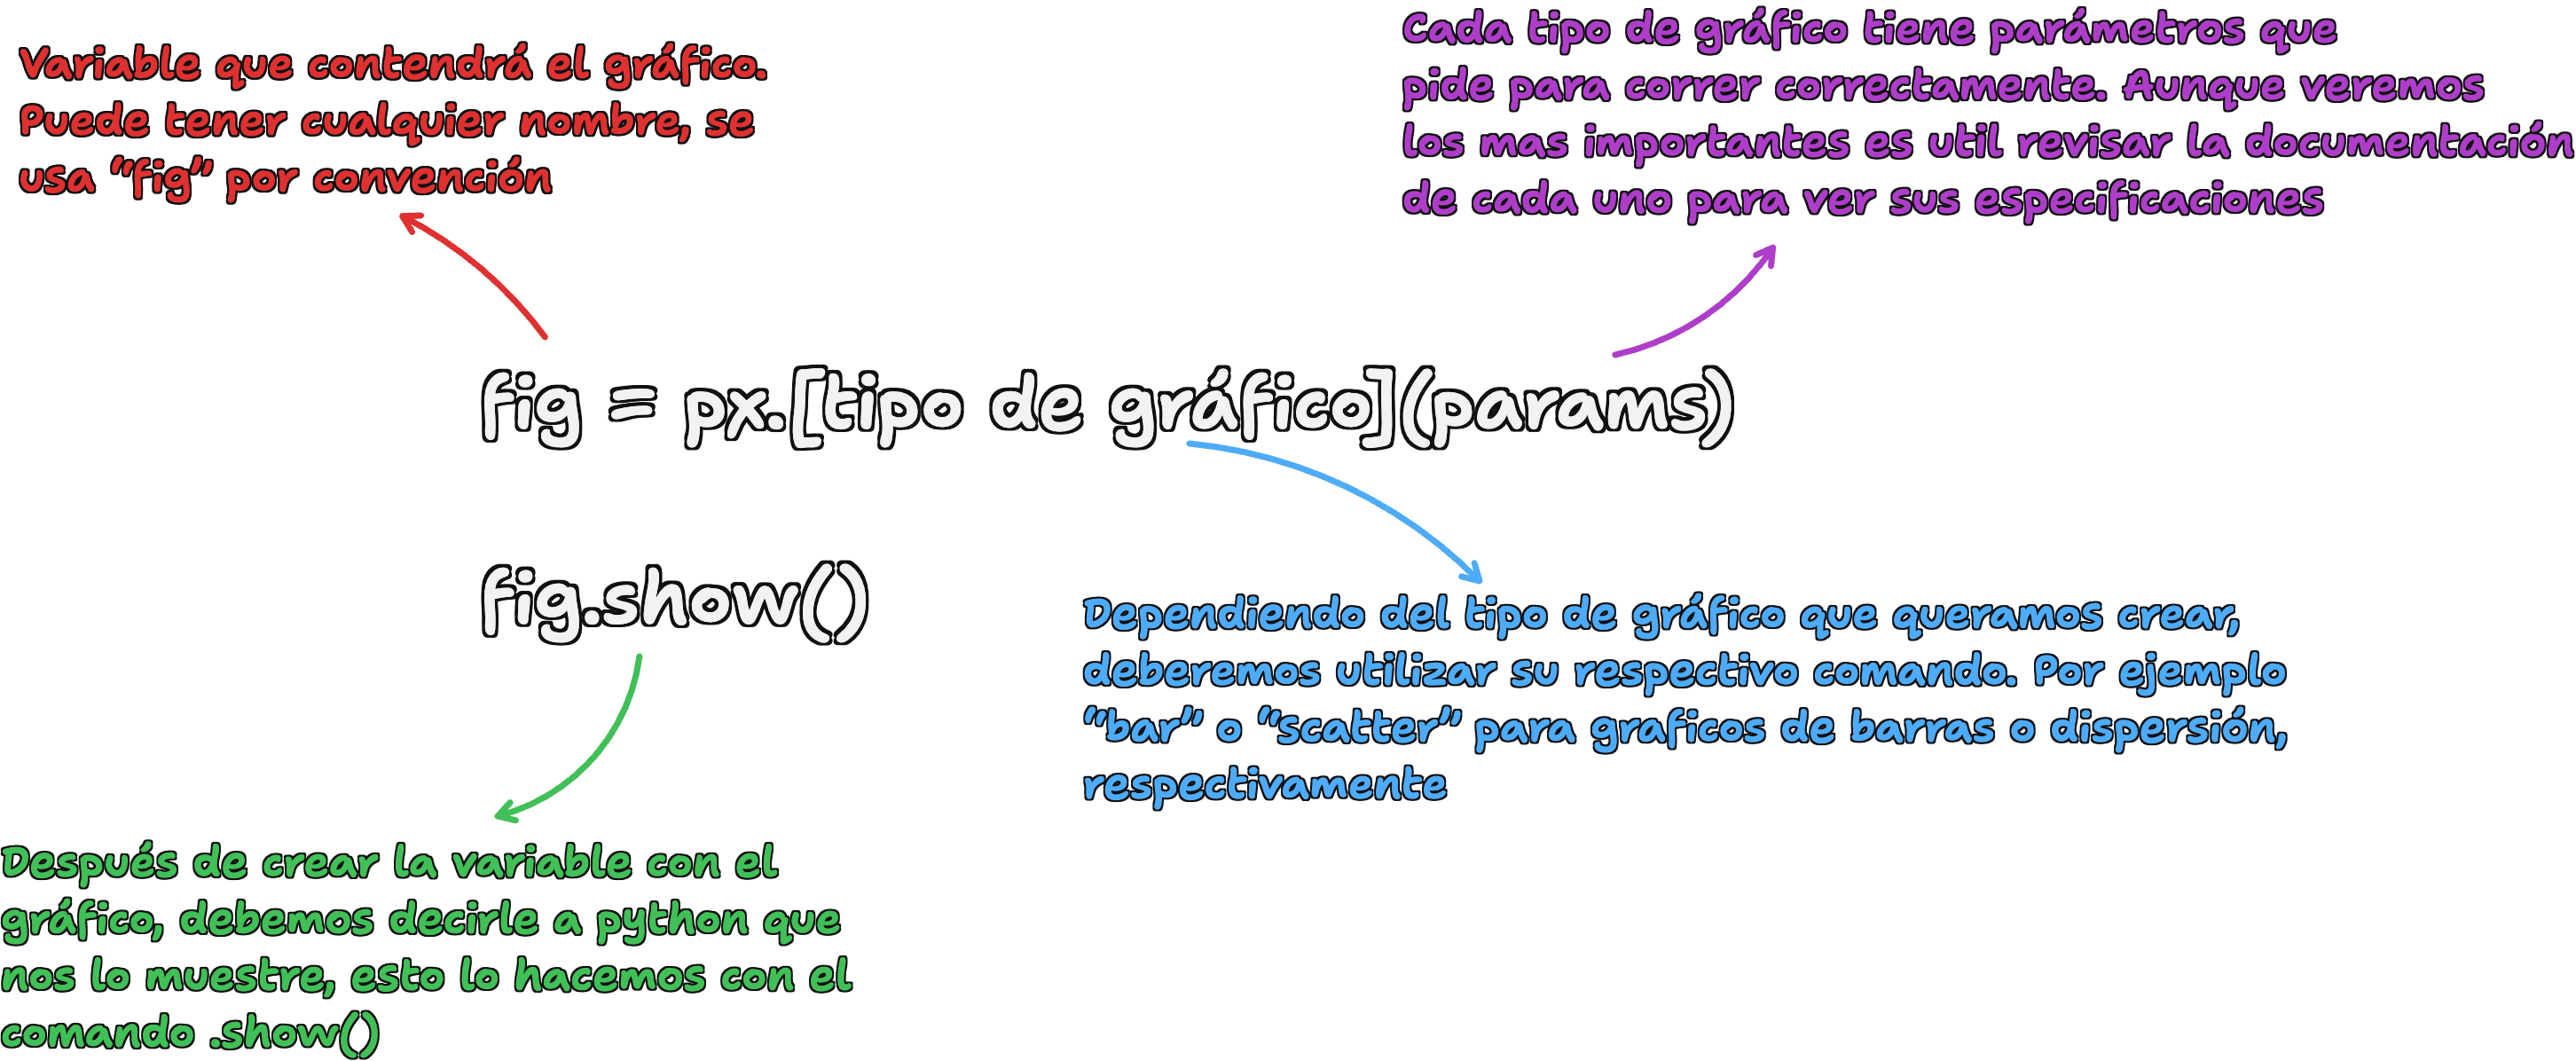


## 1. Gráfico de Barras

### ¿Qué actividad reune mas asistentes?

In [5]:
df_plot = (
    df.groupby("actividad", as_index=False)
    .agg(total_asistentes=("asistentes", "sum"))
    .sort_values(by="total_asistentes", ascending=False)
    )
df_plot

,actividad,total_asistentes
2,Lectura,8163
3,Música,6606
1,Cine,6324
4,Taller digital,4238
0,Artes,4235


In [6]:
fig = px.bar(data_frame=df_plot, x="actividad", y="total_asistentes")
fig.update_layout(title="Total Asistentes por Actividad",
                  yaxis_title="Total Asistentes",
                  xaxis_title="Tipo Actividad",
                  template="simple_white")
fig.update_traces(marker_color=["#405682", "green", "green", "green", "red"])
fig.show()

## 2. Gráfico de Pastel

In [7]:
fig = px.pie(data_frame=df_plot, values="total_asistentes", names="actividad")
fig.show()

## 3. Gráfico de Barras Apiladas

### ¿Cómo cambian los asistentes según la modalidad y la actividad?

In [8]:
df_plot = (
    df.groupby(["actividad", "modalidad"], as_index=False)
    .agg(total_asistentes=("asistentes", "sum"))
    .sort_values(by="total_asistentes", ascending=False)
    )
df_plot

,actividad,modalidad,total_asistentes
4,Lectura,Presencial,7384
6,Música,Presencial,5559
2,Cine,Presencial,5007
8,Taller digital,Presencial,3599
0,Artes,Presencial,3505
3,Cine,Virtual,1317
7,Música,Virtual,1047
5,Lectura,Virtual,779
1,Artes,Virtual,730
9,Taller digital,Virtual,639


In [9]:
fig = px.bar(data_frame=df_plot, x="actividad", y="total_asistentes", color="modalidad", barmode="group")
fig.show()

## 4. Histogramas

### ¿Cómo se distribuye los asistentes a los eventos?

In [10]:
fig = px.histogram(data_frame=df, x="asistentes", nbins=24, marginal="box")
fig.show()

## 5. Boxplot

In [11]:
fig = px.box(data_frame=df, x="asistentes")
fig.show()

### ¿Las actividades tienen la misma dispersión?

In [12]:
fig = px.box(data_frame=df, y="asistentes", x="actividad", color="actividad")
fig.show()

## 6. Diagrama de dispersión

### ¿Son las actividades que mas duran, las que tienen mayor asistencia?

In [13]:
df["duracion_falsa"] = df["duracion_min"] + np.random.normal(loc=50, scale=15, size=filas)

In [14]:
fig = px.scatter(data_frame=df, x="duracion_falsa", y="asistentes", trendline="ols", facet_col="actividad", hover_data="fecha")
fig.show()

## 7. Gráfico de línea o tendencia

### ¿Cómo cambian las asistencias a lo largo del semestre?

In [15]:
df_plot = (
    df.groupby("fecha", as_index=False)
    .agg(total_asistentes=("asistentes", "sum"))
)
df_plot

,fecha,total_asistentes
0,2026-01-01,127
1,2026-01-02,224
2,2026-01-03,160
3,2026-01-04,274
4,2026-01-05,130
...,...,...
172,2026-06-26,52
173,2026-06-27,70
174,2026-06-28,191
175,2026-06-29,187


In [16]:
fig = px.line(data_frame=df_plot, x="fecha", y="total_asistentes", markers=True)
fig.show()

## 8. Heatmap

### ¿Que combinaciones de biblioteca y actividad destacan por la satisfacción de los usuarios? 

In [17]:
df.groupby(["biblioteca", "actividad"]).agg(satisfaccion=("satisfaccion", "mean"))

satisfaccion
biblioteca                actividad                   
Bosa                      Artes               4.065000
                          Cine                3.820000
                          Lectura             4.138889
                          Música              4.323077
                          Taller digital      4.044444
El Tintal                 Artes               3.723810
                          Cine                4.081818
                          Lectura             4.189286
                          Música              4.093750
                          Taller digital      4.175000
Julio Mario Santo Domingo Artes               4.009524
                          Cine                4.027273
                          Lectura             4.146429
                          Música              4.170000
                          Taller digital      3.988000
Suba                      Artes               3.854545
                          Cine                3.985714
                          Lectura             3.930435
                          Música              3.992857
                          Taller digital      4.000000
Tunal                     Artes               4.288889
                          Cine                4.008333
                          Lectura             3.858621
                          Música              4.368750
                          Taller digital      4.216667
Virgilio Barco            Artes               3.943478
                          Cine                3.766667
                          Lectura             3.978125
                          Música              4.168000
                          Taller digital      4.032143

In [18]:
df_plot = df.pivot_table(index="biblioteca", columns="actividad", values="satisfaccion", aggfunc="mean")
df_plot

actividad,Artes,Cine,Lectura,Música,Taller digital
biblioteca,,,,,
Bosa,4.065000,3.820000,4.138889,4.323077,4.044444
El Tintal,3.723810,4.081818,4.189286,4.093750,4.175000
Julio Mario Santo Domingo,4.009524,4.027273,4.146429,4.170000,3.988000
Suba,3.854545,3.985714,3.930435,3.992857,4.000000
Tunal,4.288889,4.008333,3.858621,4.368750,4.216667
Virgilio Barco,3.943478,3.766667,3.978125,4.168000,4.032143


In [19]:
fig = px.imshow(df_plot, text_auto=".2f")
fig.show()